# 06 · Simulación de producción y capacidad

Ejecuta una prueba HTTP local con modelos exportados y almacenamiento temporal. Después concilia las predicciones históricas publicadas. No necesita Docker, Snowflake o MLflow externos.

**Alcance de validación.** 2014J ya se había observado en una versión anterior. **No es una prueba final independiente ni un hold-out de un solo uso.** Separar personas y ajustar transformaciones dentro de cada fold evita fugas directas, pero no elimina el conocimiento previo de sus resultados. Las cifras sobre 2014J describen este histórico; la decisión institucional necesita una cohorte futura sin consultar, con protocolo fijado antes de conocer resultados.

In [1]:
from pathlib import Path
import os, sys, json, hashlib
here = Path.cwd().resolve()
ROOT = next((p for p in [here, *here.parents] if (p/'src/notebooks.py').is_file()), None)
if ROOT is None and (here/'proyecto_final/src/notebooks.py').is_file():
    ROOT = here/'proyecto_final'
assert ROOT is not None, 'Abrir desde proyecto_final o notebooks.'
sys.path.insert(0, str(ROOT))
os.environ['MPLCONFIGDIR'] = str(ROOT/'.local/matplotlib')
os.environ['PSET4_MODEL_MODE'] = 'fixture'
from IPython.display import display, Markdown
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src.notebooks import evidencia
from src.datos import sha256
E = evidencia()
pd.set_option('display.max_columns', 12)
pd.set_option('display.max_rows', 32)
plt.rcParams.update({'figure.dpi': 120, 'axes.spines.top': False, 'axes.spines.right': False})
%matplotlib inline
print('Ejecución local de evidencia congelada. Sin llamadas LLM, nuevos entrenamientos ni cambios en Registry.')


Ejecución local de evidencia congelada. Sin llamadas LLM, nuevos entrenamientos ni cambios en Registry.


## API batch en dos rondas

Cuarenta matrículas sintéticas comparten cuatro cupos: uno en semana 2 y tres nuevos en semana 4. Reenviar una solicitud no consume más capacidad. La prueba no escribe en la base operativa.

In [2]:
import tempfile, copy
from fastapi.testclient import TestClient
from src.datos import Almacen, generar_ejemplo
# Evitar que la instancia global del módulo abra la base operativa.
temp=tempfile.TemporaryDirectory(prefix='oulad-notebook-')
os.environ['PSET4_DB_PATH']=str(Path(temp.name)/'global.sqlite')
from api.main import crear_app
path=Path(temp.name)/'prueba.sqlite'
generar_ejemplo(Path(temp.name),Almacen(path),'notebook-demo')
request14=json.loads((Path(temp.name)/'semana2.json').read_text())
request28=json.loads((Path(temp.name)/'semana4.json').read_text())
with TestClient(crear_app(ruta_db=path,modo='fixture')) as client:
    a=client.post('/predecir',json=request14); assert a.status_code==200
    replay=client.post('/predecir',json=request14); assert replay.json()==a.json()
    b=client.post('/predecir',json=request28); assert b.status_code==200
    invalid=copy.deepcopy(request14); del invalid['matriculas'][0]['features']['studied_credits']
    bad=client.post('/predecir',json=invalid); assert bad.status_code==422
    assert a.json()['nuevas_propuestas']==1 and b.json()['nuevas_propuestas']==3
    display(pd.DataFrame([{'corte':14,'codigo':a.status_code,'nuevas_propuestas':a.json()['nuevas_propuestas']},{'corte':28,'codigo':b.status_code,'nuevas_propuestas':b.json()['nuevas_propuestas']},{'corte':'contrato inválido','codigo':bad.status_code,'nuevas_propuestas':0}]))
temp.cleanup()


/private/tmp/pset4-cierre/venv/lib/python3.11/site-packages/fastapi/testclient.py:1: StarletteDeprecationWarning: Using `httpx` with `starlette.testclient` is deprecated; install `httpx2` instead.
  from starlette.testclient import TestClient as TestClient  # noqa


Ejemplo sintético preparado y cohorte registrada; 40 matrículas, sin etiquetas en las solicitudes.


,corte,codigo,nuevas_propuestas
0,14,200,1
1,28,200,3
2,contrato inválido,422,0


## Conciliar los ocho lotes de cada escenario

Los lotes representan despachos de una presentación histórica, no semestres distintos. El escenario de deriva es sintético y se analiza por separado. Las propuestas de semana 4 conservan las de semana 2.

,plan_id,lote_id,corte,predicciones,nuevas_propuestas
0,oulad-2014j-control-v1,L01,14,1369,33
1,oulad-2014j-control-v1,L02,14,3637,90
2,oulad-2014j-control-v1,L03,14,2750,67
3,oulad-2014j-control-v1,L04,14,1475,36
4,oulad-2014j-control-v1,L05,28,1359,103
5,oulad-2014j-control-v1,L06,28,3590,273
6,oulad-2014j-control-v1,L07,28,2684,207
7,oulad-2014j-control-v1,L08,28,1459,111
8,oulad-2014j-deriva-v1,L01,14,1369,33
9,oulad-2014j-deriva-v1,L02,14,3637,90


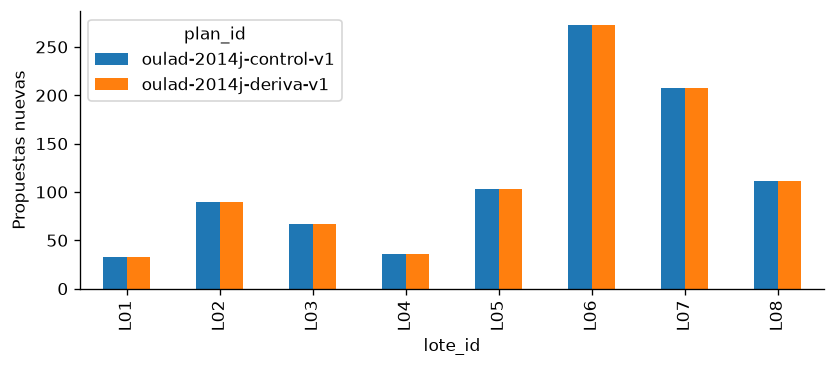

In [3]:
pred=pd.read_csv(ROOT/'docs/predicciones.csv')
assert len(pred)==36646 and not pred.id_prediccion.duplicated().any()
assert not pred.duplicated(['plan_id','cohorte_id','corte','matricula']).any()
output=pred.salida.map(json.loads)
pred['propuesta_nueva']=[r['consume_cupo_nuevo'] for r in output]
counts=pred.groupby(['plan_id','lote_id','corte']).agg(predicciones=('id_prediccion','size'),nuevas_propuestas=('propuesta_nueva','sum')).reset_index()
display(counts)
assert set(pred.version_modelo.astype(str))=={'1'}
assert pred.groupby('plan_id').propuesta_nueva.sum().eq(920).all()
assert not pred.entradas.map(json.loads).map(lambda r: bool(set(r)&{'target_class','final_result','date_unregistration'})).any()
counts.pivot(index='lote_id',columns='plan_id',values='nuevas_propuestas').plot.bar(figsize=(8,3));plt.ylabel('Propuestas nuevas');plt.show()


## Lectura final

Los resultados reproducidos pertenecen a los experimentos registrados. La fecha de ejecución de este notebook no los convierte en evidencia nueva de generalización. Consulte `README.md` para insumos, dependencias y comandos del pipeline completo.